# Phase 3 — Does Supplier Tier Correlate With Impact?
A proxy analysis for "cascade effects". This dataset is flat — one row per disruption event, with a single `supplier_tier` field and no linkage graph between tiers (we don't know which Tier-3/4 supplier feeds which Tier-1 supplier or product). So this notebook does **not** model true tier-to-tier cascades. Instead it asks a weaker but honest question: *in aggregate, do lower-tier (3/4) disruptions carry outsized production/financial/recovery impact compared to Tier-1?* That pattern, if present, is consistent with (but not proof of) cascade risk further up the chain.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path

sns.set_theme(style="whitegrid")

DATA_PATH = Path("data/processed/disruptions_clean.parquet")
df = pd.read_parquet(DATA_PATH)
df["supplier_tier"] = df["supplier_tier"].astype("Int64")
print(f"Loaded {len(df):,} rows")
df["supplier_tier"].value_counts().sort_index()

Loaded 100,000 rows


supplier_tier
1    34938
2    30023
3    25019
4    10020
Name: count, dtype: Int64

## Aggregate impact by tier
Mean/median of each impact metric, grouped by `supplier_tier`.

In [2]:
IMPACT_METRICS = ["production_impact_pct", "revenue_loss_usd", "full_recovery_days"]

tier_summary = (
    df.groupby("supplier_tier", observed=True)[IMPACT_METRICS]
    .agg(["mean", "median", "std", "count"])
    .round(2)
)
tier_summary

production_impact_pct                      revenue_loss_usd  \
                               mean median    std  count             mean   
supplier_tier                                                               
1                             37.43   36.7  18.88  34938       2960527.88   
2                             31.98   31.2  16.78  30023       2576282.68   
3                             26.49   25.9  14.68  25019       2167665.31   
4                             21.02   20.4  12.61  10020       1723124.67   

                                             full_recovery_days                \
                   median         std  count               mean median    std   
supplier_tier                                                                   
1              1071355.96  6177564.91  34938              72.34   58.0  55.31   
2               901199.80  5825918.82  30023              75.33   61.0  56.49   
3               744530.67  4651272.62  25019              79.30   64.0  58.09   
4               562274.43  3890758.66  10020              80.96   66.0  59.75   

                      
               count  
supplier_tier         
1              34938  
2              30023  
3              25019  
4              10020

## Correlation: tier vs. each impact metric
`supplier_tier` is an ordinal code (1=closest to finished product ... 4=furthest upstream). Spearman rank correlation tests whether impact rises or falls monotonically as you move away from Tier-1, without assuming a linear relationship.

In [3]:
print("Spearman correlation (supplier_tier vs. impact metric):\n")
for metric in IMPACT_METRICS:
    valid = df[["supplier_tier", metric]].dropna()
    rho, p_value = stats.spearmanr(valid["supplier_tier"], valid[metric])
    print(f"{metric:25s}  rho={rho:+.4f}   p={p_value:.4g}")

Spearman correlation (supplier_tier vs. impact metric):

production_impact_pct      rho=-0.2959   p=0
revenue_loss_usd           rho=-0.1239   p=0
full_recovery_days         rho=+0.0602   p=6.995e-81


## Statistical test: does impact differ across tiers?
One-way ANOVA (and Kruskal-Wallis as a non-parametric check) across the 4 tier groups for each metric — tests whether tier group means/distributions differ at all, regardless of direction.

In [4]:
print("ANOVA / Kruskal-Wallis across tier groups:\n")
for metric in IMPACT_METRICS:
    groups = [
        g[metric].dropna().values
        for _, g in df.groupby("supplier_tier", observed=True)
    ]
    f_stat, anova_p = stats.f_oneway(*groups)
    h_stat, kw_p = stats.kruskal(*groups)
    print(f"{metric:25s}  ANOVA p={anova_p:.4g}   Kruskal-Wallis p={kw_p:.4g}")

ANOVA / Kruskal-Wallis across tier groups:

production_impact_pct      ANOVA p=0   Kruskal-Wallis p=0
revenue_loss_usd           ANOVA p=1.101e-115   Kruskal-Wallis p=0
full_recovery_days         ANOVA p=1.274e-66   Kruskal-Wallis p=6.009e-79


## Visualize impact distributions by tier

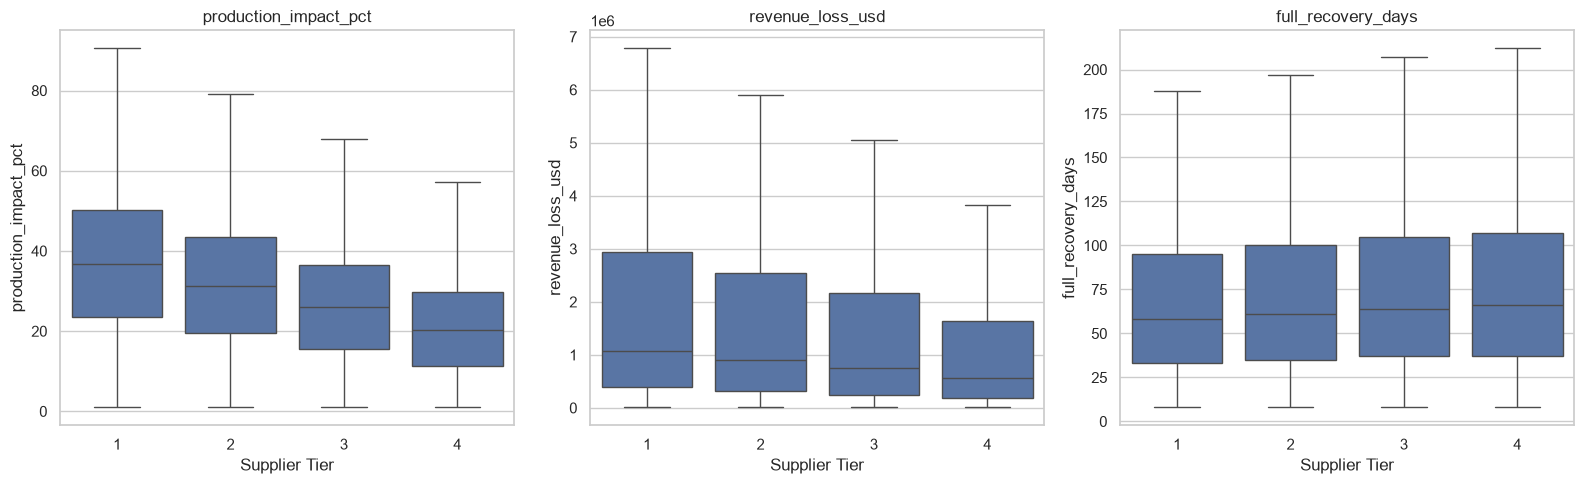

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, metric in zip(axes, IMPACT_METRICS):
    sns.boxplot(data=df, x="supplier_tier", y=metric, ax=ax, showfliers=False)
    ax.set_title(metric)
    ax.set_xlabel("Supplier Tier")

plt.tight_layout()
plt.show()

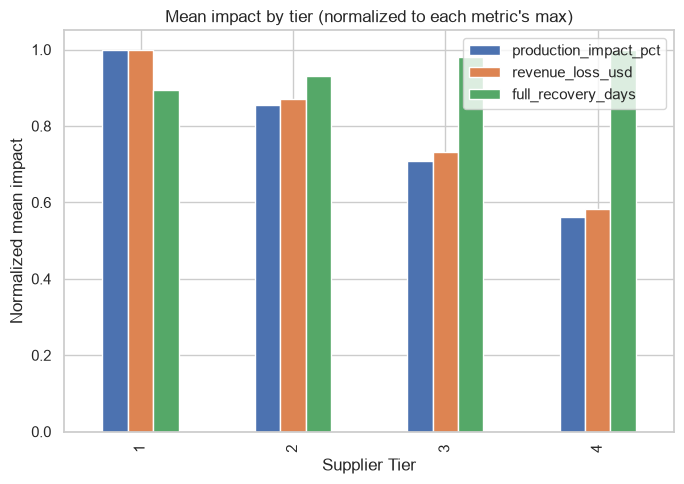

In [6]:
fig, ax = plt.subplots(figsize=(7, 5))
tier_means = df.groupby("supplier_tier", observed=True)[IMPACT_METRICS].mean()
tier_means_norm = tier_means / tier_means.max()  # normalize to 0-1 for comparability
tier_means_norm.plot(kind="bar", ax=ax)
ax.set_title("Mean impact by tier (normalized to each metric's max)")
ax.set_xlabel("Supplier Tier")
ax.set_ylabel("Normalized mean impact")
plt.tight_layout()
plt.show()

## Interpretation
- A negative Spearman rho means impact tends to be *higher* at Tier-1 (closer to finished product) and lower further upstream; a positive rho means the opposite — lower tiers (3/4) show *higher* impact, which would support the idea that deep-tier disruptions ripple into outsized downstream consequences.
- A significant ANOVA/Kruskal-Wallis p-value (< 0.05) means tier groups are not statistically identical on that metric, regardless of direction.
- **Caveat**: this is a population-level association across ~100k independent disruption events, not a traced cascade from a specific Tier-4 event to a specific Tier-1 outcome. Treat any pattern here as a hypothesis for where to prioritize monitoring, not as a causal cascade model.